# 02 · Member 2 analysis: Routing, Duration, FX conversions
**Owner:** Ong Wan Ning · **Needs:** run `04_integration_validation.ipynb` first.

For each rule: write the hypothesis → test it on the full data → chart it with the rule as its title → save it to `outputs/` → add a row to `outputs/tables/rules/rules_02.csv` → run `combine_rules()`.

**Scope of this notebook**
- `TRANSACTION_TYPE_CODE` (Direct / Indirect / Covered) **is** the routing type, so routing and transaction type form one group.
- Builds on, does not repeat: R-CCY2 / R-CCY3 (FX), R-BC2 (timing), N4 (type/hour → amount, rejected).
- Every `save_table()` output in `outputs/tables/` is small and aggregated: import **these** into Power BI, not the parquet.

### Evidence policy (updated 18 Nov 2026)
- **One verdict system, two kinds of rule** (column `verdict_basis` in `evidence_matrix.csv`):
  - *Accuracy rules* state a deterministic prediction (e.g. "Direct ⇔ 2 banks"). They are graded by the share of tested rows that obey them: `Confirmed` ≥ 99% · `Strong` 95–99% · `Partial` 70–95% · `Weak` below that. The tested denominator and any exclusions are always shown.
  - *Effect rules* state a size, an independence or a distribution (e.g. "×7.4 per business party").
    - `Supported`: the stated effect holds **and** the out-of-sample (holdout) estimate agrees with it, by the criterion written in `holdout_rule`, e.g. overlapping 95% CIs.
    - `Approximate`: the direction is right, but the holdout disagrees, is missing, or the model misses. The reason is in `verdict_note`.
    - `Rejected` or `Inconclusive` otherwise.
- **Causal status** says how far the evidence goes. It describes the evidence, not proof of the generator's code.
  - `Mechanism`: needs a 95% CI, an out-of-sample check, a subgroup check and a practical meaning. Rules lacking any of these are automatically downgraded.
  - `Association`: a real, stable pattern whose cause is not identified.
  - `Structural`: true by how the fields are defined.
  - `Rejected`: the stated prediction fails.
  - `Unresolved`: the tested method found no support but cannot rule the mechanism out.
- **Interpretations** ("consistent with …", "plausibly …") are possible explanations, not proven causes. "No measurable association" is not proof of independence, and "no detectable difference" is not proof that something is random.
- **Local time** uses clock offsets inferred from the CSV under stated assumptions (Monday–Friday week, no summer time, one offset per country). They are not verified time zones, and office-hour results on that clock are partly built into the offsets.
- **READY** (end of notebook 04) means every file comes from the current code and data, and every required piece of evidence is present and consistent. It does not prove that a rule is the generator's actual code.
- **Accounts** are always identified by **(BIC8, account number)**, because 2.4% of receiver account numbers recur at several banks.
- **Data used:** only the organiser CSV. Local currency and each country's clock offset are **inferred from the CSV itself**; the clock offsets come from the training period only. No time-zone database, currency table or GDP data enters any calculation.
- Saved outputs are cleared in this pack. Re-run in the order 04 → 01 → 02 → 03 → 04 before quoting any number.

In [1]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [2]:
con = connect()

In [3]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Weak (<70%) · Rejected (prediction fails)'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Weak'

def combine_rules():
    """Combine standardized teammate rule tables and flag unfinished placeholders.

    Running notebook 04 *first* creates its core rules; re-run the final
    consolidation cell after notebooks 01-03 to capture every teammate's work.
    """
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        aliases = {'observed_evidence_table_or_chart': 'evidence_files',
                   'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={a:b for a,b in aliases.items() if a in d and b not in d})
        if 'rule' not in d and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d['when_condition'].fillna('') + ' -> ' + d['then_effect'].fillna('')
        if 'value' not in d and 'size' in d: d['value'] = d['size']
        for col in RULE_COLS:
            if col not in d: d[col] = ''
        d['source'] = f.name
        frames.append(d)
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=RULE_COLS+['source'])
    required = {'rules_04_core.csv','rules_02.csv','rules_03_anomalies.csv'}
    missing = sorted(required - {f.name for f in RULES.glob('rules_*.csv')})
    dup = out['id'].astype(str).duplicated(keep=False) if len(out) else []
    unfinished = out.astype(str).apply(lambda col: col.str.contains(r'TODO|\?\?|A2-example', case=False, regex=True)).any(axis=1) if len(out) else []
    if missing: print('INTEGRATION INCOMPLETE — missing:', ', '.join(missing))
    if len(out) and any(dup): print('INTEGRATION WARNING — repeated rule IDs:', out.loc[dup,'id'].tolist())
    if len(out) and any(unfinished): print('INTEGRATION WARNING — unresolved template cells:', out.loc[unfinished,'id'].tolist())
    out = out[ RULE_COLS + ['source'] + [c for c in out if c not in RULE_COLS + ['source']] ]
    out.to_csv(TAB/'rules_log.csv', index=False)
    return out

In [4]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


In [5]:
# Evidence toolkit (identical in every notebook): 95% CIs, tests, a time-based train/test split and causal labels
from scipy import stats
EVID_COLS = ['id', 'statistic_ci', 'p_value', 'out_of_sample', 'invariance', 'causal_status', 'practical_significance',
             'holdout_agrees', 'holdout_rule']   # holdout_agrees: does the out-of-sample estimate agree with the stated effect / CI?
CAUSAL = {   # how strongly a rule is a cause-and-effect rule of the generator (used in every evidence_*.csv)
    'Mechanism':   'consistent with a generator rule: holds after controls, out of sample and in every subgroup tested, and a placebo / '
                   'negative control shows no effect (supported by the data, not proof of the generator code)',
    'Structural':  'true by how the fields are built (a definition or an accounting identity), not a behavioural finding',
    'Association': 'real and stable pattern, but the data cannot show why: an unobserved cause is possible',
    'Rejected':    'the stated prediction fails, or the pattern is explained away by a confounder',
    'Unresolved':  'the tested method found no support, but it cannot rule the mechanism out (e.g. matching may miss links)'}
# A rule may be called 'Mechanism' only with ALL of these filled in; notebook 04 downgrades it to 'Association' otherwise
MECHANISM_NEEDS = ['statistic_ci', 'out_of_sample', 'invariance', 'practical_significance']

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a share k/n (stays inside 0-100%, works for 0% and 100%)."""
    if not n: return np.nan, np.nan
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def share_ci(k, n, digits=2):
    """'97.80% [97.78%, 97.82%], n = 1,234' for a share k/n."""
    if not n: return 'n = 0'
    lo, hi = wilson(k, n); f = f'{{:.{digits}%}}'
    return f'{f.format(k / n)} [{f.format(lo)}, {f.format(hi)}], n = {int(n):,}'

def two_prop(k1, n1, k2, n2):
    """Share difference (group 1 - group 2), its 95% CI and a two-sided z-test p-value."""
    if not n1 or not n2: return np.nan, (np.nan, np.nan), np.nan
    p1, p2 = k1 / n1, k2 / n2; pp = (k1 + k2) / (n1 + n2)
    se0 = np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2)); se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    pval = 2 * stats.norm.sf(abs(p1 - p2) / se0) if se0 > 0 else (0.0 if p1 != p2 else 1.0)
    return p1 - p2, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se), pval

def paired_prop(a, b):
    """Two yes/no outcomes measured on the SAME rows (e.g. office hour on local clock vs UTC): McNemar test.
    Returns share(a) - share(b), its 95% CI and the p-value; only the discordant rows carry information."""
    a, b = np.asarray(a, bool), np.asarray(b, bool); n = len(a)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum()); d = (n10 - n01) / n
    se = np.sqrt(max(n10 + n01 - (n10 - n01) ** 2 / n, 0)) / n
    pval = stats.binomtest(n10, n10 + n01).pvalue if 0 < n10 + n01 < 1000 else (2 * stats.norm.sf(abs(n10 - n01) / np.sqrt(n10 + n01)) if n10 + n01 else 1.0)
    return d, (d - 1.96 * se, d + 1.96 * se), pval

def cramers_v_ct(ct):
    ct = np.asarray(ct, float); chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.sum() * (min(ct.shape) - 1)))

def v_ci(ct, reps=200, seed=0):
    """Cramér's V with a 95% CI (multinomial bootstrap of the contingency table)."""
    ct = np.asarray(ct, float); rng = np.random.default_rng(seed); n = int(ct.sum())
    boot = [cramers_v_ct(rng.multinomial(n, (ct / n).ravel()).reshape(ct.shape) + 1e-9) for _ in range(reps)]
    return cramers_v_ct(ct), np.percentile(boot, [2.5, 97.5])

def fmt_p(p):
    if p is None or not np.isfinite(p): return 'p = n/a'
    return 'p < 1e-300' if p == 0 else f'p = {p:.1e}' if p < 1e-3 else f'p = {p:.3f}'

def median_ci(x):
    """Distribution-free 95% CI of a median from order statistics (no bootstrap needed)."""
    x = np.sort(np.asarray(x)); n = len(x)
    if n == 0: return np.nan, np.nan
    h = 1.96 * np.sqrt(n) / 2
    return x[max(0, int(np.floor(n / 2 - h)))], x[min(n - 1, int(np.ceil(n / 2 + h)))]

# Out-of-sample check by TIME: a rule is fitted on the first 2/3 of the data window and re-tested on the last 1/3
T_SPLIT = int(con.execute("SELECT quantile_disc(EPOCH_SECONDS, 2/3) FROM p").fetchall()[0][0])
print('train = before', pd.to_datetime(T_SPLIT, unit='s'), 'UTC; test = after')

import hashlib, json as _json
def code_hash(prefix):
    """Fingerprint of a notebook's CODE cells as saved on disk (outputs ignored): proves which code version made a file."""
    f = sorted((ROOT / 'notebooks').glob(f'{prefix}_*.ipynb'))
    if not f: return ''
    cells = _json.loads(f[0].read_text(encoding='utf-8'))['cells']
    return hashlib.sha1('\n'.join(''.join(c['source']) for c in cells if c['cell_type'] == 'code').encode()).hexdigest()[:12]
DATA_STAMP = f"{FULL.stat().st_size}-{int(FULL.stat().st_mtime)}"      # identifies the data build the results came from

def overlap(a, b):
    """True if two intervals (lo, hi) overlap: used to say a holdout estimate agrees with the full-data estimate."""
    return bool(max(a[0], b[0]) <= min(a[1], b[1]))
def holdout(ok, rule):
    return dict(holdout_agrees=bool(ok), holdout_rule=rule)

def save_evidence(rows, name):
    """rows: dicts with EVID_COLS -> outputs/tables/rules/evidence_<name>.csv (merged into the evidence matrix by notebook 04).
    Each file also records the code version (code_hash) and the data build (data_stamp) it came from."""
    e = pd.DataFrame(rows).reindex(columns=EVID_COLS)
    e['code_hash'], e['data_stamp'] = code_hash(name), DATA_STAMP
    bad = set(e.causal_status.dropna()) - set(CAUSAL)
    assert not bad, f'unknown causal_status {bad}'
    e.to_csv(RULES / f'evidence_{name}.csv', index=False); return e

train = before 2023-06-28 12:22:04 UTC; test = after


In [6]:
# Sender-local time from clock offsets INFERRED FROM THE DATA in notebook 04 (section 1b): no external time-zone table.
# (Before: an external time-zone package. Now both notebooks use the same data-only offsets, so R-BC2 and N-DUR1 agree.)
CLK = PROC / 'clock_offsets.csv'
assert CLK.exists(), 'clock_offsets.csv missing: run notebooks/04_integration_validation.ipynb first'
clk = pd.read_csv(CLK, keep_default_na=False, na_values=[''])[['cc', 'offset_hours']]   # keep_default_na: 'NA' = Namibia
con.register('clk_df', clk); con.execute("CREATE OR REPLACE TABLE clk AS SELECT * FROM clk_df")
# Same missing-offset policy as notebook 01: a country without an inferred offset gets NULL local time and is left out
LOCAL_SQL = """(((({t}.EPOCH_SECONDS + z.offset_hours * 3600)::BIGINT) // 3600) % 24)::INT AS local_hour,
               (((({t}.EPOCH_SECONDS + z.offset_hours * 3600)::BIGINT) // 86400 + 3) % 7 + 1)::INT AS local_wd"""
print('sender countries without an inferred offset (left out of local-time tests):',
      sql("SELECT DISTINCT o_cc FROM p WHERE o_cc NOT IN (SELECT cc FROM clk) ORDER BY 1").o_cc.tolist())

# pl = full data + sender-local hour and ISO weekday (1 = Mon ... 7 = Sun)
con.execute(f"CREATE OR REPLACE VIEW pl AS SELECT p.*, {LOCAL_SQL.format(t='p')} FROM p LEFT JOIN clk z ON p.o_cc = z.cc")

# Pandas sample for charts / models (includes anomalies; sn = normal payments only)
s = sql(f"SELECT s.*, {LOCAL_SQL.format(t='s')} FROM read_parquet('{SAMPLE.as_posix()}') s LEFT JOIN clk z ON s.o_cc = z.cc")
s['ly'] = np.log(s.TOTAL_DURATION)
sn = s[s.anomaly == 'NONE'].copy()
print(f'sample: {len(s):,} rows, normal: {len(sn):,}')

def r2(df, cols, y='ly'):
    """Share of variance in y explained by the group means of cols (eta squared)."""
    cols = [cols] if isinstance(cols, str) else list(cols)
    # group means via ngroup + bincount: the multi-column groupby().transform('mean') gave R² = 1.000 on pandas 3 / full data
    codes = df.groupby(cols, observed=True, sort=False).ngroup().fillna(-1).to_numpy().astype(np.int64)
    v = df[y].to_numpy(float); ok = (codes >= 0) & np.isfinite(v); c, v = codes[ok], v[ok]
    gm = np.bincount(c, v) / np.bincount(c)
    return 1 - ((v - gm[c]) ** 2).sum() / ((v - v.mean()) ** 2).sum()

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight'); plt.show()

TYPES = ['Direct', 'Indirect', 'Covered']

def cramers_v(t):
    """Cramér's V of a contingency table of counts (0 = independent)."""
    t = np.asarray(t, float); e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
    return float(np.sqrt(((t - e) ** 2 / e).sum() / (t.sum() * (min(t.shape) - 1))))

def additive_r2(df, cols, y='ly', iters=10):
    """R² of an additive model y ~ effect[col1] + effect[col2] + ... (backfitting; no interaction cells)."""
    # numpy backfitting (the pandas groupby().transform version returned 1.000 on the laptop's pandas)
    v = df[y].to_numpy(float); ok = np.isfinite(v); v = v[ok]
    codes = [pd.factorize(df[c])[0][ok] for c in cols]
    r = v - v.mean(); eff = [np.zeros(len(v)) for _ in cols]
    for _ in range(iters):
        for i, c in enumerate(codes):
            part = r + eff[i]; eff[i] = (np.bincount(c, part) / np.bincount(c))[c]; r = part - eff[i]
    return 1 - (r ** 2).sum() / ((v - v.mean()) ** 2).sum()

sender countries without an inferred offset (left out of local-time tests): ['AF', 'BF', 'BI', 'CF', 'DM', 'FM', 'FO', 'GA', 'GD', 'GF', 'GI', 'GL', 'GM', 'GP', 'GQ', 'HT', 'JM', 'KI', 'KM', 'KP', 'LR', 'LS', 'MG', 'MH', 'MP', 'MS', 'MW', 'NR', 'PM', 'PW', 'RE', 'SC', 'SH', 'SO', 'ST', 'SZ', 'TC', 'TD', 'TT', 'VC', 'VU', 'WS']


sample: 2,001,857 rows, normal: 2,000,487


## Feature group: Routing (`TRANSACTION_TYPE_CODE`)
**Hypotheses**
- H-RT1: Direct payments always have exactly 2 participants; Indirect and Covered add intermediary banks.
- H-RT2: The path starts at the ordering BIC and ends at the beneficiary BIC.
- H-RT3: Once the `...` gap and repeated BICs are removed, the number of distinct banks on the path equals `PARTICIPANT_COUNT`.
- H-RT4: The routing type depends on whether the payment is cross-border, on the B/C pair, or on anomalies.

In [7]:
# H-RT1: hop count by routing type
rt1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, count(*) n,
       round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY TRANSACTION_TYPE_CODE), 2) pct
FROM p GROUP BY 1, 2 ORDER BY 1, 2"""), 'rt1_hops_by_type')
rt1_share = sql("SELECT avg(((TRANSACTION_TYPE_CODE = 'Direct') = (PARTICIPANT_COUNT = 2))::INT) FROM p").iloc[0, 0]
print(f'Direct <=> 2 participants holds in {rt1_share:.4%} of rows')
rt1.pivot(index='PARTICIPANT_COUNT', columns='TRANSACTION_TYPE_CODE', values='pct').fillna(0)

Direct <=> 2 participants holds in 100.0000% of rows


TRANSACTION_TYPE_CODE,Covered,Direct,Indirect
PARTICIPANT_COUNT,,,
2,0.00,100.0,0.00
3,63.24,0.0,63.21
4,23.22,0.0,23.27
5,8.56,0.0,8.54
6,3.14,0.0,3.15
7,1.16,0.0,1.16
8,0.43,0.0,0.42
9,0.16,0.0,0.16
10,0.06,0.0,0.06


In [8]:
# H-RT2 / H-RT3: path endpoints and path length vs PARTICIPANT_COUNT
rt2 = save_table(sql("""
WITH x AS (SELECT TRANSACTION_TYPE_CODE, path_gap, path_len, PARTICIPANT_COUNT, ORDERING_BIC8, BENEFICIARY_BIC8,
                  string_split(BIC8_PATH, ';') AS l FROM p)
SELECT TRANSACTION_TYPE_CODE, path_gap, count(*) n,
       avg((l[1] = ORDERING_BIC8)::INT)        AS starts_at_ordering_bic,
       avg((l[-1] = BENEFICIARY_BIC8)::INT)    AS ends_at_beneficiary_bic,
       avg((path_len = PARTICIPANT_COUNT)::INT) AS path_len_eq_participants,
       avg((len(list_distinct(list_filter(l, lambda b: b <> '...'))) = PARTICIPANT_COUNT)::INT) AS distinct_banks_eq_participants,
       avg((len(list_filter(l, lambda b: b <> '...')) > len(list_distinct(list_filter(l, lambda b: b <> '...'))))::INT) AS has_repeated_bic
FROM x GROUP BY 1, 2 ORDER BY 1, 2"""), 'rt2_path_vs_participants')
w = lambda col, mask=slice(None): np.average(rt2.loc[mask, col], weights=rt2.loc[mask, 'n'])
rt2_start, rt2_end = w('starts_at_ordering_bic'), w('ends_at_beneficiary_bic')
rt3_share = w('distinct_banks_eq_participants', ~rt2.path_gap)
print(f'path starts at ordering BIC {rt2_start:.2%}, ends at beneficiary BIC {rt2_end:.2%}; '
      f'distinct banks = participants (no gap) {rt3_share:.2%}')
rt2

path starts at ordering BIC 95.02%, ends at beneficiary BIC 95.01%; distinct banks = participants (no gap) 99.47%


,TRANSACTION_TYPE_CODE,path_gap,n,starts_at_ordering_bic,ends_at_beneficiary_bic,path_len_eq_participants,distinct_banks_eq_participants,has_repeated_bic
0,Covered,False,364700,0.950688,0.949737,1.0,0.973770,2.622978e-02
1,Covered,True,51262,0.950646,0.951446,0.0,0.964360,3.564044e-02
2,Direct,False,6008014,0.950148,0.950008,1.0,0.999999,9.986661e-07
3,Direct,True,315266,0.950718,0.950220,0.0,1.000000,0.000000e+00
4,Indirect,False,2860082,0.950020,0.950201,1.0,0.986149,1.385135e-02
5,Indirect,True,400676,0.950354,0.950157,0.0,0.979594,2.040551e-02


In [9]:
# H-RT2 follow-up: when the path does NOT start at the ordering BIC, which country does it start in?
save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, cross_border,
       substr(string_split(BIC8_PATH, ';')[1], 5, 2) = o_cc AS first_bank_same_country,
       count(*) n
FROM p WHERE string_split(BIC8_PATH, ';')[1] <> ORDERING_BIC8
GROUP BY ALL ORDER BY n DESC LIMIT 20"""), 'rt2_first_bank_mismatch')

,TRANSACTION_TYPE_CODE,cross_border,first_bank_same_country,n
0,Direct,True,False,284559
1,Indirect,True,False,146854
2,Covered,True,False,18732
3,Direct,False,False,15258
4,Direct,True,True,12782
5,Indirect,False,False,8095
6,Indirect,True,True,6698
7,Direct,False,True,2448
8,Indirect,False,True,1191
9,Covered,False,False,826


In [10]:
# H-RT5: the '...' gap. Is there an independent ~5% chance of a gap on every link between two consecutive banks?
rt5 = sql("""SELECT PARTICIPANT_COUNT, count(*) n, avg(path_gap::INT) gap_rate
             FROM p GROUP BY 1 HAVING count(*) >= 1000 ORDER BY 1""")
q_link = rt5.loc[rt5.PARTICIPANT_COUNT == 2, 'gap_rate'].iloc[0]          # Direct = 1 link -> per-link gap chance
rt5['predicted_per_link'] = 1 - (1 - q_link) ** (rt5.PARTICIPANT_COUNT - 1)
rt5_maxerr = (rt5.gap_rate - rt5.predicted_per_link).abs().max()
save_table(rt5, 'rt5_gap_by_participants')
# Is each path length within SAMPLING ERROR of the per-link model? q comes from Direct rows only, so every longer path length
# is an independent check: chi-square goodness of fit on the standardised errors (an absolute 0.5-point cut-off ignores that
# long paths have few rows: 10 banks = ~2,200 rows, standard error ~1 point)
_m5 = rt5.PARTICIPANT_COUNT > 2
_z5 = (rt5.gap_rate - rt5.predicted_per_link) * np.sqrt(rt5.n / (rt5.predicted_per_link * (1 - rt5.predicted_per_link)))
rt5_chi = float((_z5[_m5] ** 2).sum()); rt5_df = int(_m5.sum()); rt5_gof_p = float(stats.chi2.sf(rt5_chi, rt5_df))
rt5_zmax = float(_z5[_m5].abs().max()); rt5_zpc = int(rt5.PARTICIPANT_COUNT[_z5[_m5].abs().idxmax()])
print(f"per-link gap chance {q_link:.4f}; largest gap between observed and predicted rate: {rt5_maxerr:.4f}; "
      f"goodness of fit chi-square {rt5_chi:.1f} on {rt5_df} df, {fmt_p(rt5_gof_p)} (largest |z| {rt5_zmax:.1f} at {rt5_zpc} banks)")
rt5

per-link gap chance 0.0499; largest gap between observed and predicted rate: 0.0139; goodness of fit chi-square 13.5 on 8 df, p = 0.097 (largest |z| 2.4 at 7 banks)


,PARTICIPANT_COUNT,n,gap_rate,predicted_per_link
0,2,6323280,0.049858,0.049858
1,3,2324319,0.097410,0.097230
2,4,855386,0.142464,0.142240
3,5,314014,0.184957,0.185007
4,6,115701,0.225270,0.225641
5,7,42622,0.269274,0.264249
6,8,15481,0.308378,0.300932
7,9,5758,0.330497,0.335786
8,10,2205,0.382766,0.368902


In [11]:
# H-RT6: number of intermediary banks is geometric (each further intermediary added with the same chance q)
rt6 = sql("SELECT PARTICIPANT_COUNT - 2 AS intermediaries, count(*) n FROM p GROUP BY 1 ORDER BY 1")
rt6['share'] = rt6.n / rt6.n.sum()
q_hop = 1 - rt6.share.iloc[0]                                              # chance of at least one more intermediary
rt6['predicted'] = (1 - q_hop) * q_hop ** rt6.intermediaries
rt6['ratio_to_previous'] = rt6.share / rt6.share.shift()
rt6_tvd = 0.5 * (rt6.share - rt6.predicted).abs().sum()                   # total variation distance, 0 = identical
save_table(rt6, 'rt6_intermediaries_geometric')
print(f"q = {q_hop:.4f} (1/e = {np.exp(-1):.4f}); distance observed vs geometric = {rt6_tvd:.4f}")
rt6.head(10)

q = 0.3677 (1/e = 0.3679); distance observed vs geometric = 0.0001


,intermediaries,n,share,predicted,ratio_to_previous
0,0,6323280,0.632328,0.632328,NaN
1,1,2324319,0.232432,0.232489,0.367581
2,2,855386,0.085539,0.085480,0.368016
3,3,314014,0.031401,0.031429,0.367102
4,4,115701,0.011570,0.011555,0.368458
5,5,42622,0.004262,0.004249,0.368381
6,6,15481,0.001548,0.001562,0.363216
7,7,5758,0.000576,0.000574,0.371940
8,8,2205,0.000220,0.000211,0.382945
9,9,769,0.000077,0.000078,0.348753


In [12]:
# Lead for the currency teammate (R-CCY1): is the payment currency the local currency of the FIRST BANK ON THE PATH
# (which differs from the ordering BIC in ~5% of rows) rather than of the ordering BIC?
lead = sql("""
SELECT (string_split(BIC8_PATH, ';')[1] = ORDERING_BIC8) AS path_starts_at_ordering_bic, count(*) n,
       avg((CURRENCY_CODE = lo.local_ccy)::INT) AS ccy_is_ordering_country_local,
       avg((CURRENCY_CODE = lf.local_ccy)::INT) AS ccy_is_first_bank_local
FROM p LEFT JOIN local_ccy lo ON p.o_cc = lo.cc
       LEFT JOIN local_ccy lf ON substr(string_split(p.BIC8_PATH, ';')[1], 5, 2) = lf.cc
GROUP BY 1""")
save_table(lead, 'rt2_currency_vs_first_bank')

,path_starts_at_ordering_bic,n,ccy_is_ordering_country_local,ccy_is_first_bank_local
0,False,498399,0.138638,0.934757
1,True,9501601,0.934126,0.934126


In [13]:
# H-RT4: does routing type depend on cross-border / B-C pair / anomaly?  (row % within each group + Cramér's V)
rt4, rt4_v = {}, {}
for col in ['cross_border', 'pair', 'anomaly']:
    d = sql(f"""SELECT {col}::VARCHAR AS grp, TRANSACTION_TYPE_CODE t, count(*) n FROM p GROUP BY 1, 2""")
    t = d.pivot(index='grp', columns='t', values='n').fillna(0)
    rt4_v[col] = cramers_v(t)
    rt4[col] = (t.div(t.sum(1), axis=0) * 100).round(2).assign(n=t.sum(1))
    save_table(rt4[col].reset_index(), f'rt4_type_by_{col}')
    print(f"{col}: Cramér's V = {rt4_v[col]:.4f}"); display(rt4[col])
cov_dom, cov_xb = rt4['cross_border'].loc['false', 'Covered'], rt4['cross_border'].loc['true', 'Covered']

cross_border: Cramér's V = 0.0459


t,Covered,Direct,Indirect,n
grp,,,,
false,7.34,63.25,29.41,711116
true,3.92,63.23,32.85,9288884


pair: Cramér's V = 0.0024


t,Covered,Direct,Indirect,n
grp,,,,
B2B,4.09,63.22,32.69,2270945
B2C,4.22,63.23,32.55,5603692
C2B,4.08,63.19,32.73,610605
C2C,4.08,63.28,32.64,1514758


anomaly: Cramér's V = 0.0032


t,Covered,Direct,Indirect,n
grp,,,,
ACCOUNT_REPLACEMENT_SCAM,0.46,68.26,31.28,649
CEO_SCAM,0.74,62.65,36.61,945
CUSTOMER_RECALL,4.73,58.99,36.28,317
DUPLICATE_PAYMENT,4.57,60.09,35.35,679
FAT_FINGER_MISTAKE,4.54,65.52,29.95,1940
NONE,4.16,63.23,32.61,9992994
ROMANCE_SCAM,0.12,60.34,39.54,2476


In [14]:
# Evidence (routing): 95% CIs, invariance (month, domestic vs cross-border, Indirect vs Covered), the geometric model
# fitted on the first 2/3 of time and tested on the last 1/3, and the practical meaning
cnt = sql(f"""SELECT strftime(ts, '%Y-%m') AS month, TRANSACTION_TYPE_CODE t, cross_border, pair, EPOCH_SECONDS >= {T_SPLIT} AS test,
                     PARTICIPANT_COUNT pc, path_gap, count(*) n, sum(USD_AMOUNT) usd FROM p GROUP BY ALL""")
big_month = cnt.groupby('month').n.sum()[lambda x: x >= 0.02 * cnt.n.sum()].index
def share(d, cond): return d.loc[cond(d), 'n'].sum() / d.n.sum()
by = lambda col, cond, d=cnt: d.groupby(col).apply(lambda g: share(g, cond))
more = lambda d: d.pc > 2                                                 # at least one intermediary bank
q_k, q_n = cnt.loc[more(cnt), 'n'].sum(), cnt.n.sum()
cont = pd.DataFrame([(f'P(>={j - 2} intermediaries | >={j - 3})', cnt.loc[cnt.pc > j - 1, 'n'].sum(), cnt.loc[cnt.pc > j - 2, 'n'].sum())
                     for j in range(4, 8)], columns=['step', 'k', 'n'])
cont['ratio'] = cont.k / cont.n; cont[['lo', 'hi']] = [wilson(k, m) for k, m in zip(cont.k, cont.n)]
q_month, q_xb = by('month', more, cnt[cnt.month.isin(big_month)]), by('cross_border', more)
q_type = by('t', lambda d: d.pc > 3, cnt[cnt.t != 'Direct'])             # Indirect / Covered: chance of a 2nd intermediary
tr_c, te_c = cnt[~cnt.test], cnt[cnt.test]
q_tr = share(tr_c, more); te_d = te_c.groupby(te_c.pc - 2).n.sum(); te_d = te_d / te_d.sum()
tvd_test = 0.5 * np.abs(te_d.values - (1 - q_tr) * q_tr ** te_d.index.values).sum()
dl = cnt[cnt.pc == 2]; g_k, g_n = dl.loc[dl.path_gap, 'n'].sum(), dl.n.sum()
gap_month = by('month', lambda d: d.path_gap, dl[dl.month.isin(big_month)])
ct_pair = cnt.pivot_table(index='pair', columns='t', values='n', aggfunc='sum'); p_pair = stats.chi2_contingency(ct_pair)[1]
cov = cnt.groupby('cross_border').apply(lambda d: pd.Series({'k': d.loc[d.t == 'Covered', 'n'].sum(), 'n': d.n.sum()}))
d_cov, ci_cov, p_cov = two_prop(cov.loc[False, 'k'], cov.loc[False, 'n'], cov.loc[True, 'k'], cov.loc[True, 'n'])
cov_month = cnt[cnt.month.isin(big_month)].groupby(['month', 'cross_border']).apply(lambda d: share(d, lambda x: x.t == 'Covered')).unstack()
rt3_len = np.average(rt2.loc[~rt2.path_gap, 'path_len_eq_participants'], weights=rt2.loc[~rt2.path_gap, 'n'])
# R-RT2 endpoints, R-RT5 per-link gaps, R-RT7 independence and R-RT8 Covered share: test period + month-by-month checks
rt2t = sql(f"""SELECT strftime(ts, '%Y-%m') AS month, EPOCH_SECONDS >= {T_SPLIT} AS test, count(*) n,
                  sum((split_part(BIC8_PATH, ';', 1) = ORDERING_BIC8)::INT) s_ok,
                  sum((list_last(string_split(BIC8_PATH, ';')) = BENEFICIARY_BIC8)::INT) e_ok FROM p GROUP BY ALL""")
r2s_ = rt2t.sum(numeric_only=True); r2te = rt2t[rt2t.test].sum(numeric_only=True)
r2m = rt2t[rt2t.month.isin(big_month)].groupby('month')[['n', 's_ok', 'e_ok']].sum()
q_link_tr = share(dl[~dl.test], lambda d: d.path_gap)
gte = cnt[cnt.test].groupby('pc').apply(lambda d: pd.Series({'n': d.n.sum(), 'gap': share(d, lambda x: x.path_gap)}))
gte = gte[gte.n >= 1000]; rt5_err_test = (gte.gap - (1 - (1 - q_link_tr) ** (gte.index - 1))).abs().max()
_pr5 = 1 - (1 - q_link_tr) ** (gte.index - 1)
rt5_chi_te = float((((gte.gap - _pr5) ** 2) * gte.n / (_pr5 * (1 - _pr5))).sum()); rt5_df_te = len(gte); rt5_gof_p_te = float(stats.chi2.sf(rt5_chi_te, rt5_df_te))
v_rt7, v_rt7_ci = v_ci(ct_pair.values)
v_rt7_te = cramers_v_ct(cnt[cnt.test].pivot_table(index='pair', columns='t', values='n', aggfunc='sum').values)
v_rt7_m = {m: cramers_v_ct(g.pivot_table(index='pair', columns='t', values='n', aggfunc='sum').values) for m, g in cnt[cnt.month.isin(big_month)].groupby('month')}
cov_te = cnt[cnt.test].groupby('cross_border').apply(lambda d: pd.Series({'k': d.loc[d.t == 'Covered', 'n'].sum(), 'n': d.n.sum()}))
d_cov_te, ci_cov_te, _ = two_prop(cov_te.loc[False, 'k'], cov_te.loc[False, 'n'], cov_te.loc[True, 'k'], cov_te.loc[True, 'n'])
usd_multi = cnt.loc[more(cnt), 'usd'].sum() / cnt.usd.sum()
display(cont.round(4)); print('q by month', q_month.round(4).to_dict(), '| q domestic/cross-border', q_xb.round(4).to_dict())
ev02 = [
 dict(id='R-RT1', statistic_ci=share_ci(rt1_share * q_n, q_n, 4), causal_status='Structural', out_of_sample='holds by definition in every period',
      practical_significance=f'{1 - q_k / q_n:.1%} of payments settle bank-to-bank; the rest need at least one correspondent'),
 dict(id='R-RT6', statistic_ci=f'q = {share_ci(q_k, q_n, 2)}',
      p_value='memoryless check (each step should equal q): ' + '; '.join(f'{r.ratio:.3f}' for r in cont.itertuples()),
      out_of_sample=f'q fitted on train = {q_tr:.4f}; distance to the test-period hop distribution {tvd_test:.4f}',
      invariance=f"by month {q_month.min():.4f}-{q_month.max():.4f}; domestic {q_xb.get(False, np.nan):.4f} vs cross-border {q_xb.get(True, np.nan):.4f}; "
                 f"2nd intermediary Indirect {q_type.get('Indirect', np.nan):.4f} vs Covered {q_type.get('Covered', np.nan):.4f}",
      causal_status='Mechanism', practical_significance=f'{usd_multi:.1%} of USD value passes through at least one intermediary bank (fees + delay)',
      **holdout(tvd_test < 0.005, 'geometric model fitted on train predicts the test-period hop distribution within a distance of 0.005')),
 dict(id='R-RT3', statistic_ci=f'{rt3_len:.2%} of complete paths', causal_status='Structural', practical_significance='-'),
 dict(id='R-RT2', statistic_ci=f'start {share_ci(r2s_.s_ok, r2s_.n)}; end {share_ci(r2s_.e_ok, r2s_.n)}', causal_status='Association',
      out_of_sample=f'test period: start {r2te.s_ok / r2te.n:.2%}, end {r2te.e_ok / r2te.n:.2%}',
      **holdout(abs(r2te.s_ok / r2te.n - r2s_.s_ok / r2s_.n) < 0.005 and abs(r2te.e_ok / r2te.n - r2s_.e_ok / r2s_.n) < 0.005, 'test-period shares within 0.5 points of the full data'),
      invariance=f'by month start {(r2m.s_ok / r2m.n).min():.2%}-{(r2m.s_ok / r2m.n).max():.2%}, end {(r2m.e_ok / r2m.n).min():.2%}-{(r2m.e_ok / r2m.n).max():.2%}',
      practical_significance='about 1 in 20 payments is processed by a bank other than the account-holding BIC: screening must use the path, not only the BIC columns'),
 dict(id='R-RT5', statistic_ci=f'per-link gap chance {share_ci(g_k, g_n, 2)}',
      p_value=f'goodness of fit vs per-link model: chi-square {rt5_chi:.1f} on {rt5_df} df, {fmt_p(rt5_gof_p)}; largest error {rt5_maxerr:.4f} (|z| = {rt5_zmax:.1f} at {rt5_zpc} banks)',
      out_of_sample=f'gap chance fitted on train Direct rows = {q_link_tr:.4f}; test-period goodness of fit chi-square {rt5_chi_te:.1f} on {rt5_df_te} df, {fmt_p(rt5_gof_p_te)} (largest error {rt5_err_test:.4f})',
      **holdout(rt5_gof_p_te >= 0.01, 'per-link model fitted on train Direct rows is not rejected on the test period (goodness of fit p >= 0.01)'),
      invariance=f'by month {gap_month.min():.4f}-{gap_month.max():.4f}', causal_status='Mechanism' if rt5_gof_p >= 0.01 else 'Association',
      practical_significance=f"{share(cnt[cnt.pc > 2], lambda d: d.path_gap):.1%} of multi-bank payments have an untraceable step ('...')"),
 dict(id='R-RT7', statistic_ci=f"V = {v_rt7:.4f} [{v_rt7_ci[0]:.4f}, {v_rt7_ci[1]:.4f}]",
      out_of_sample=f'test period V = {v_rt7_te:.4f}', invariance=f'by month V {min(v_rt7_m.values()):.4f}-{max(v_rt7_m.values()):.4f}',
      **holdout(v_rt7_te < 0.01, 'test-period V below 0.01 (negligible association)'), p_value=f'chi-square {fmt_p(p_pair)} (huge n: any tiny difference is "significant"; V is the size)',
      causal_status='Mechanism', practical_significance='routing type carries no information about whether a business or a consumer is paying: B/C must come from the party fields'),
 dict(id='R-RT8', statistic_ci=f'Covered domestic - cross-border {d_cov:+.2%} [{ci_cov[0]:+.2%}, {ci_cov[1]:+.2%}]', p_value=fmt_p(p_cov),
      out_of_sample=f'test period {d_cov_te:+.2%} [{ci_cov_te[0]:+.2%}, {ci_cov_te[1]:+.2%}]',
      **holdout(ci_cov_te[0] > 0 and overlap(ci_cov, ci_cov_te), 'test-period difference CI above 0 and overlapping the full-data CI'),
      invariance='by month: domestic ' + ', '.join(f'{v:.2%}' for v in cov_month[False]) + '; cross-border ' + ', '.join(f'{v:.2%}' for v in cov_month[True]),
      causal_status='Association', practical_significance='counter-intuitive vs real banking (cover payments are normally cross-border): treat as a generator feature'),
]

,step,k,n,ratio,lo,hi
0,P(>=2 intermediaries | >=1),1352401,3676720,0.3678,0.3673,0.3683
1,P(>=3 intermediaries | >=2),497015,1352401,0.3675,0.3667,0.3683
2,P(>=4 intermediaries | >=3),183001,497015,0.3682,0.3669,0.3695
3,P(>=5 intermediaries | >=4),67300,183001,0.3678,0.3656,0.3700


q by month {'2023-05': 0.3678, '2023-06': 0.3677, '2023-07': 0.3676} | q domestic/cross-border {False: 0.3675, True: 0.3677}


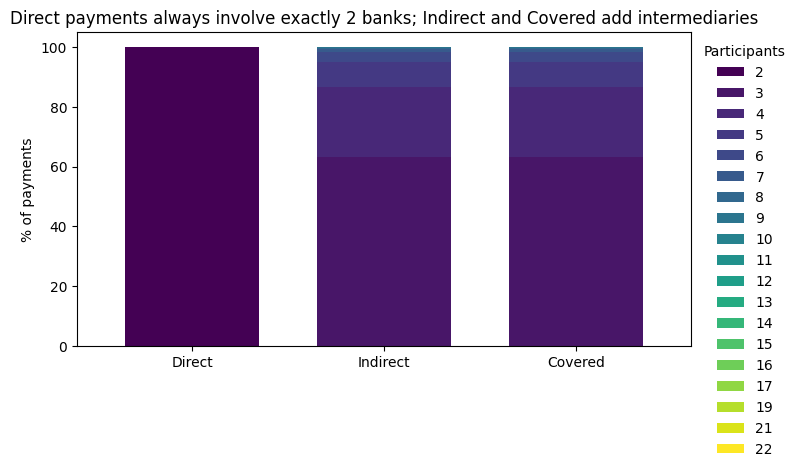

In [15]:
# Chart: hop count by routing type
d = rt1.pivot(index='PARTICIPANT_COUNT', columns='TRANSACTION_TYPE_CODE', values='pct').fillna(0)[TYPES]
ax = d.T.plot.bar(stacked=True, figsize=(8, 4.5), colormap='viridis', width=0.7)
ax.set_title(f'Direct payments always involve exactly 2 banks; Indirect and Covered add intermediaries')
ax.set_xlabel(''); ax.set_ylabel('% of payments'); ax.legend(title='Participants', bbox_to_anchor=(1, 1), frameon=False)
plt.xticks(rotation=0); savefig('rt1_hops_by_type')

**Findings (Routing)** (numbers from the full 10M rows; ⟳ = value is printed by a cell above, check it after the run)
- **R-RT1 Direct = exactly 2 banks** (100%). Indirect and Covered always have ≥ 3. *Meaning:* a Direct payment needs a bilateral account between the two banks; otherwise correspondent banks relay it.
- **R-RT6 Number of intermediaries is geometric:** 63.2% have none (Direct), 23.2% one, 8.6% two, 3.1% three … each extra intermediary is ~0.37× as common as the one before (⟳ `q`, distance to the geometric model). Indirect and Covered have the **same** hop distribution. *Meaning:* banks use the shortest correspondent chain available; long chains are rare.
- **R-RT3 `PARTICIPANT_COUNT` = number of BIC entries on the path, repeats counted** (100% of complete paths). A BIC appears twice in 1.4% of Indirect and 2.6% of Covered paths, never in Direct.
- **R-RT2 The path starts at the ordering BIC and ends at the beneficiary BIC in 95.0% of rows** (each end), the same for every routing type. When the first bank differs, it is usually in another country. *Meaning:* a parent/branch BIC or an outsourced sending bank. ⟳ Check `rt2_currency_vs_first_bank`: if the payment currency follows the first bank, this explains part of R-CCY1's exceptions → tell the currency teammate.
- **R-RT5 The `...` gap:** 5.0% of Direct vs 12.3% of Indirect/Covered paths. An independent ~5% chance per link predicts the gap rate of every path length within sampling error (⟳ chi-square goodness of fit printed above).
- **R-RT7 Routing type is independent of the B/C pair:** Direct 63.2% in B2B, B2C, C2B and C2C alike (⟳ Cramér's V).
- **R-RT8 Domestic payments are routed Covered almost twice as often:** 7.3% vs 3.9% cross-border; the Direct share is identical (63.2%). *Counter-intuitive:* in practice the cover method is used for cross-border payments, so flag it as a data-generation feature.
- **For Member 3 (anomalies):** scams are almost never Covered: romance 0.12%, CEO 0.74%, account-replacement 0.46% vs 4.16% for normal payments.

**Evidence strength (Routing)** (⟳ = `ev02` values, saved in `outputs/tables/rules/evidence_02.csv`)
- **R-RT6 geometric hops:** the "memoryless" check passes, i.e. the chance of one more intermediary is ≈ q at every step. q is the same every month, for domestic and cross-border payments, and for Indirect and Covered. The q fitted on the first 2/3 of the time window predicts the last 1/3 (distance ≈ 0). **Mechanism.**
- **R-RT5 gap per link:** narrow Wilson CI (⟳) and the same every month. The per-link model is tested with a chi-square goodness of fit over all path lengths (q from Direct rows only), on the full data and on the test period (q learned on train). It is a **Mechanism** only if neither test rejects it (p ≥ 0.01). The largest absolute miss (~1.4 points at 10 banks) comes from a group of only ~2,200 rows, where the standard error is ~1 point, so it is within sampling error. This shows the data are consistent with independent gaps; it does not prove the generator draws them that way.
- **R-RT1 / R-RT3:** **Structural** (they follow from how `PARTICIPANT_COUNT` and the path are built).
- **R-RT2 / R-RT8:** **Association**. R-RT8 has a tight CI and is stable by month, but it runs against real-world practice, so it is presented as a generator feature, not a banking mechanism.
- **Practical significance:** ⟳ the share of USD value that passes through at least one intermediary (extra fees and delay), and the share of multi-bank payments with an untraceable step.


## Feature group: Duration (`TOTAL_DURATION`)
**Hypotheses**
- H-DUR1: Duration depends on the routing type (Direct < Indirect < Covered).
- H-DUR2: Within each routing type, every extra participant adds time.
- H-DUR3: Sender-local hour / weekday changes duration (e.g. payments sent after hours or at weekends wait longer).
- H-DUR4: Amount, B/C pair, cross-border and anomaly have no extra effect once routing is known.

In [16]:
# H-DUR1 / H-DUR2: duration by routing type and hop count (full data)
dur1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, count(*) n,
       median(TOTAL_DURATION) med, quantile_cont(TOTAL_DURATION, 0.1) p10, quantile_cont(TOTAL_DURATION, 0.9) p90,
       exp(avg(ln(TOTAL_DURATION))) geo_mean
FROM p WHERE anomaly = 'NONE' GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur1_by_type_hops')
med_type = sql("SELECT TRANSACTION_TYPE_CODE t, median(TOTAL_DURATION) med FROM p WHERE anomaly='NONE' GROUP BY 1").set_index('t').med
print(med_type.round(0).to_dict())
dur1

{'Covered': 383.0, 'Indirect': 281.0, 'Direct': 39.0}


,TRANSACTION_TYPE_CODE,PARTICIPANT_COUNT,n,med,p10,p90,geo_mean
0,Covered,3,262970,288.0,22.0,2517.0,213.755542
1,Covered,4,96538,445.0,31.0,2913.0,325.829023
2,Covered,5,35574,587.0,43.0,3352.0,468.219584
3,Covered,6,13079,752.0,55.0,3618.8,608.448929
4,Covered,7,4823,941.0,69.0,4040.4,761.469685
5,Covered,8,1768,1130.0,96.7,4327.7,928.416625
6,Covered,9,685,1413.0,183.2,4633.2,1143.432475
7,Covered,10,238,1807.0,253.6,4830.8,1306.959446
8,Covered,11,92,1893.0,237.1,5185.3,1514.752530
9,Covered,12,30,1385.5,622.1,4264.0,1498.194288


In [17]:
# Factor screening on ln(duration): R² alone, and extra R² on top of routing type + hops
sn['amt_decile'] = pd.qcut(np.log(sn.USD_AMOUNT), 10, labels=False)
base = ['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']
r2_base = r2(sn, base)
cands = ['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT', 'CURRENCY_CONVERSION_COUNT', 'path_gap', 'cross_border',
         'pair', 'local_hour', 'local_wd', 'o_cc', 'b_cc', 'amt_decile']
def extra_r2(c):
    """Extra R² of c beyond type + hops, on rows where c is known (local time is missing for countries without an offset)."""
    d = sn[sn[c].notna()]; return r2(d, base + [c]) - r2(d, base)
dur_r2 = pd.DataFrame({'r2_alone': {c: r2(sn, c) for c in cands},
                       'extra_r2_given_type_hops': {c: extra_r2(c) if c not in base else np.nan for c in cands}}
                      ).sort_values('r2_alone', ascending=False).round(4)
print(f'R² of routing type + hops together: {r2_base:.3f}')
save_table(dur_r2.reset_index(names='factor'), 'dur2_factor_screening')

R² of routing type + hops together: 0.046


,factor,r2_alone,extra_r2_given_type_hops
0,PARTICIPANT_COUNT,0.0460,NaN
1,o_cc,0.0419,0.0450
2,CURRENCY_CONVERSION_COUNT,0.0389,0.0004
3,b_cc,0.0382,0.0408
4,TRANSACTION_TYPE_CODE,0.0339,NaN
5,path_gap,0.0012,0.0000
6,amt_decile,0.0006,0.0007
7,cross_border,0.0006,0.0007
8,pair,0.0000,0.0001
9,local_hour,0.0000,0.0001


In [18]:
# Anomalies: do anomalous payments take longer than normal ones with the same routing?
save_table(sql("""
SELECT anomaly, count(*) n, median(TOTAL_DURATION) med,
       median(TOTAL_DURATION / PARTICIPANT_COUNT) med_per_participant
FROM p GROUP BY 1 ORDER BY med DESC"""), 'dur4_by_anomaly')

,anomaly,n,med,med_per_participant
0,ROMANCE_SCAM,2476,1148.0,473.5
1,CEO_SCAM,945,741.0,270.5
2,ACCOUNT_REPLACEMENT_SCAM,649,571.0,234.5
3,DUPLICATE_PAYMENT,679,261.0,115.5
4,NONE,9992994,56.0,23.0
5,CUSTOMER_RECALL,317,53.0,22.5
6,FAT_FINGER_MISTAKE,1940,53.0,22.5


In [19]:
# H-DUR2: sender and receiver country (Direct payments only, so routing is fixed). Additive model, no interaction.
dd = sn[sn.TRANSACTION_TYPE_CODE == 'Direct']
dur_cc = pd.Series({'sender country': r2(dd, 'o_cc'), 'receiver country': r2(dd, 'b_cc'),
                    'sender + receiver (additive)': additive_r2(dd, ['o_cc', 'b_cc'])}).round(4)
print(dur_cc)
cc_speed = sql("""SELECT o_cc AS country, count(*) n, median(TOTAL_DURATION) med_duration_as_sender
                  FROM p WHERE anomaly = 'NONE' AND TRANSACTION_TYPE_CODE = 'Direct' GROUP BY 1 HAVING count(*) >= 5000
                  ORDER BY med_duration_as_sender""")
save_table(cc_speed, 'dur2_country_speed_direct')
pd.concat([cc_speed.head(5).assign(rank='fastest'), cc_speed.tail(5).assign(rank='slowest')])

sender country                  0.0505
receiver country                0.0459
sender + receiver (additive)    0.0907
dtype: float64


,country,n,med_duration_as_sender,rank
0,UG,7161,21.0,fastest
1,PY,8527,22.0,fastest
2,SX,7469,23.0,fastest
3,LI,37143,23.0,fastest
4,DO,5872,24.0,fastest
93,BR,13566,1631.0,slowest
94,AO,5001,1659.0,slowest
95,LB,9450,1825.0,slowest
96,SK,5134,2130.0,slowest
97,HR,6364,3119.0,slowest


In [20]:
# H-DUR3: duration by sender-local hour and weekday (normal payments)
dur3 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, local_hour, count(*) n, median(TOTAL_DURATION) med
FROM pl WHERE anomaly = 'NONE' AND local_hour IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur3_by_local_hour')
dur3w = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, local_wd, count(*) n, median(TOTAL_DURATION) med
FROM pl WHERE anomaly = 'NONE' AND local_hour IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur3_by_local_weekday')
dur3w.pivot(index='local_wd', columns='TRANSACTION_TYPE_CODE', values='med')[TYPES]

TRANSACTION_TYPE_CODE,Direct,Indirect,Covered
local_wd,,,
1,39.0,281.0,382.0
2,39.0,279.0,383.0
3,39.0,275.0,388.0
4,39.0,281.0,381.0
5,39.0,280.0,382.0
6,39.0,287.0,375.0
7,39.0,281.0,377.0


In [21]:
# Evidence (duration): CIs for the medians, out-of-sample check of the country model, a robustness check for the
# scam delay (same routing type and hop count) and the size of the effects in minutes
dm = sql(f"""SELECT TRANSACTION_TYPE_CODE t, EPOCH_SECONDS >= {T_SPLIT} test, strftime(ts, '%Y-%m') AS month, median(TOTAL_DURATION) med, count(*) n
             FROM p WHERE anomaly = 'NONE' GROUP BY ALL""")
dm = dm[dm.n >= 1000]
med_ci = {t: median_ci(sn.loc[sn.TRANSACTION_TYPE_CODE == t, 'TOTAL_DURATION']) for t in TYPES}
ratio_month = dm.pivot_table(index='month', columns='t', values='med', aggfunc='mean')
ratio_month = (ratio_month.Indirect / ratio_month.Direct).dropna()
# exact medians of ALL normal payments in each period (not an average of monthly medians)
med_test = sql(f"""SELECT EPOCH_SECONDS >= {T_SPLIT} AS test, TRANSACTION_TYPE_CODE t, median(TOTAL_DURATION) med
                   FROM p WHERE anomaly = 'NONE' GROUP BY ALL""").pivot(index='test', columns='t', values='med')
def additive_fit(df, cols, y='ly', iters=10):
    """Additive country effects y ~ mu + a[sender] + b[receiver] (backfitting); returns mu and one effect table per column."""
    mu = df[y].mean(); r = df[y] - mu; eff = {c: pd.Series(0.0, index=df.index) for c in cols}; tab = {}
    for _ in range(iters):
        for c in cols:
            part = r + eff[c]; tab[c] = part.groupby(df[c], observed=True).mean(); eff[c] = df[c].map(tab[c]); r = part - eff[c]
    return mu, tab
dd_tr, dd_te = dd[dd.EPOCH_SECONDS < T_SPLIT], dd[dd.EPOCH_SECONDS >= T_SPLIT]
mu, tab = additive_fit(dd_tr, ['o_cc', 'b_cc'])
pred = mu + sum(dd_te[c].map(t).fillna(0) for c, t in tab.items())
r2_cc_oos = 1 - ((dd_te.ly - pred) ** 2).sum() / ((dd_te.ly - dd_te.ly.mean()) ** 2).sum()
# Scam delay at the SAME routing type and hop count: ratio of medians inside each cell, then Mann-Whitney on the per-cell rank
an = sql("""SELECT anomaly, TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, TOTAL_DURATION FROM p
            WHERE anomaly IN ('ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM', 'DUPLICATE_PAYMENT', 'FAT_FINGER_MISTAKE')""")
cell_med = sn.groupby(['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']).TOTAL_DURATION.median().rename('cell_med')
an = an.join(cell_med, on=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']).dropna()
ref = sn.join(cell_med, on=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']); ref_x = np.log(ref.TOTAL_DURATION / ref.cell_med).sort_values(ignore_index=True)
scam_adj = {}
for a, g in an.groupby('anomaly'):
    x = np.log(g.TOTAL_DURATION / g.cell_med)
    scam_adj[a] = (np.exp(x.median()), stats.mannwhitneyu(x, ref_x.sample(min(200_000, len(ref_x)), random_state=0)).pvalue, len(g))
scam_adj = pd.DataFrame(scam_adj, index=['x_vs_normal_same_routing', 'mann_whitney_p', 'n']).T
save_table(scam_adj.reset_index(names='anomaly'), 'dur5_anomaly_delay_same_routing'); display(scam_adj)
# R-DUR2: month-by-month R² of the additive country model (R² has no simple CI: a bootstrap inflates it, because resampled
# duplicates over-fit small countries, so the honest uncertainty statements are the out-of-sample R² and the monthly spread)
dd_m = pd.to_datetime(dd.EPOCH_SECONDS, unit='s').dt.strftime('%Y-%m')
dur2_month = {m: additive_r2(dd[dd_m == m], ['o_cc', 'b_cc']) for m in dd_m.value_counts()[lambda x: x >= 0.02 * len(dd)].index.sort_values()}
# R-DUR3: CI of the same-routing delay ratio (order-statistic CI of the median log ratio), test period, and by routing type
an_t = sql(f"""SELECT anomaly, EPOCH_SECONDS >= {T_SPLIT} AS test, TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, TOTAL_DURATION FROM p
               WHERE anomaly IN ('ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM', 'DUPLICATE_PAYMENT', 'FAT_FINGER_MISTAKE')""")
an_t = an_t.join(cell_med, on=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']).dropna(); an_t['x'] = np.log(an_t.TOTAL_DURATION / an_t.cell_med)
dur3_ci = {a: tuple(np.exp(median_ci(g.x))) for a, g in an_t.groupby('anomaly')}
dur3_te = an_t[an_t.test].groupby('anomaly').x.median().pipe(np.exp)
dur3_type = an_t[an_t.TRANSACTION_TYPE_CODE != 'Covered'].groupby(['anomaly', 'TRANSACTION_TYPE_CODE']).x.median().pipe(np.exp).unstack()
slow = sql("SELECT avg((TOTAL_DURATION > 3600)::INT) h1, avg((TOTAL_DURATION > 600)::INT) m10 FROM p WHERE anomaly = 'NONE'").iloc[0]
ev02 += [
 dict(id='R-DUR1', statistic_ci='median (95% CI): ' + ', '.join(f'{t} {med_type[t]:.0f}s [{med_ci[t][0]:.0f}, {med_ci[t][1]:.0f}]' for t in TYPES),
      out_of_sample='test-period medians: ' + ', '.join(f"{t} {med_test.loc[True, t]:.0f}s" for t in TYPES if t in med_test.columns),
      invariance=f'Indirect / Direct median ratio by month x{ratio_month.min():.1f}-x{ratio_month.max():.1f}', causal_status='Mechanism',
      **holdout(all(abs(med_test.loc[True, t] / med_type[t] - 1) < 0.05 for t in TYPES) and med_test.loc[True, 'Direct'] < med_test.loc[True, 'Indirect'] < med_test.loc[True, 'Covered'],
                'test-period medians within 5% of the full-data medians and in the same order Direct < Indirect < Covered'),
      practical_significance=f"a correspondent route adds ~{(med_type['Indirect'] - med_type['Direct']) / 60:.0f} min at the median; "
                             f"{slow.m10:.0%} of normal payments take > 10 min, {slow.h1:.0%} > 1 hour (R² only {r2_base:.3f}: individual times are unpredictable)"),
 dict(id='R-DUR2', statistic_ci=f"additive R² {dur_cc['sender + receiver (additive)']:.3f} (Direct, 20% sample; point estimate, see out-of-sample R² and monthly spread)",
      invariance='by month R² ' + ', '.join(f'{m} {v:.3f}' for m, v in dur2_month.items()),
      out_of_sample=f'country effects fitted on train, R² on test {r2_cc_oos:.3f}', causal_status='Association',
      **holdout(r2_cc_oos >= 0.8 * dur_cc['sender + receiver (additive)'], 'out-of-sample R² at least 80% of the in-sample R²'),
      practical_significance=f'median Direct duration by sender country ranges {cc_speed.med_duration_as_sender.min():.0f}s-{cc_speed.med_duration_as_sender.max():,.0f}s '
                             f'(x{cc_speed.med_duration_as_sender.max() / cc_speed.med_duration_as_sender.min():.0f}): speed promises must be country-specific'),
 dict(id='R-DUR3', statistic_ci='same routing type + hops: ' + ', '.join(f'{a} x{r.x_vs_normal_same_routing:.1f} [{dur3_ci[a][0]:.1f}, {dur3_ci[a][1]:.1f}]' for a, r in scam_adj.iterrows()),
      out_of_sample='test period: ' + ', '.join(f'{a} x{v:.1f}' for a, v in dur3_te.items()),
      **holdout(all(dur3_ci[a][0] <= dur3_te.get(a, np.nan) <= dur3_ci[a][1] for a in ['ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM'] if a in dur3_ci),
                'test-period delay of each scam type inside its full-data 95% CI'),
      invariance='Direct / Indirect: ' + ', '.join(f"{a} x{r.get('Direct', np.nan):.1f} / x{r.get('Indirect', np.nan):.1f}" for a, r in dur3_type.iterrows()),
      p_value='Mann-Whitney vs normal: ' + ', '.join(f'{a} {fmt_p(r.mann_whitney_p)}' for a, r in scam_adj.iterrows()),
      causal_status='Association', practical_significance='scam payments take several times longer than comparable normal payments: duration is a usable red flag (see notebook 03 detectors); the reason (e.g. a screening hold) is not observed'),
 dict(id='N-DUR1', statistic_ci=f"extra R² hour {dur_r2.loc['local_hour', 'extra_r2_given_type_hops']:.4f}, weekday {dur_r2.loc['local_wd', 'extra_r2_given_type_hops']:.4f} (sender clock inferred from data)",
      causal_status='Rejected', practical_significance='no material night or weekend slowdown was found (negligible extra R²); a zero effect is not proven'),
]

,x_vs_normal_same_routing,mann_whitney_p,n
ACCOUNT_REPLACEMENT_SCAM,5.765101,1.920089e-15,649.0
CEO_SCAM,7.666667,1.065955e-26,945.0
DUPLICATE_PAYMENT,1.251678,4.078801e-02,679.0
FAT_FINGER_MISTAKE,1.025641,9.407832e-01,1940.0
ROMANCE_SCAM,13.884609,9.316288e-170,2476.0


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


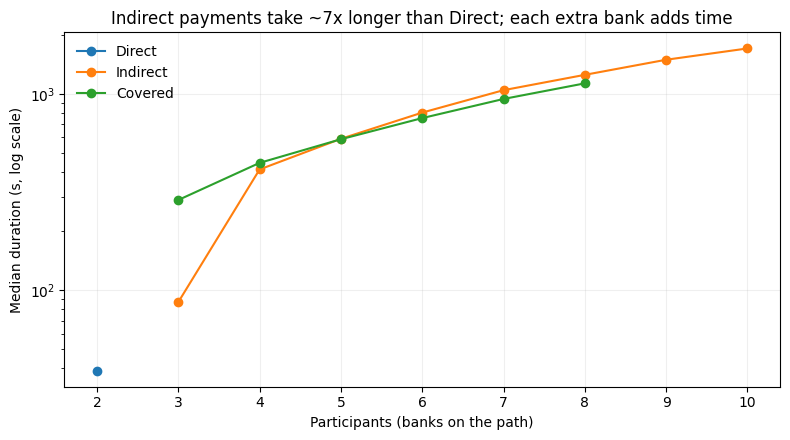

In [22]:
# Chart 1: duration by routing type and hops
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in TYPES:
    d = dur1[(dur1.TRANSACTION_TYPE_CODE == t) & (dur1.n >= 1000)]
    ax.plot(d.PARTICIPANT_COUNT, d.med, marker='o', label=t)
ax.set_yscale('log'); ax.set_xlabel('Participants (banks on the path)'); ax.set_ylabel('Median duration (s, log scale)')
ratio = med_type.get('Indirect', np.nan) / med_type.get('Direct', np.nan)
ax.set_title(f'Indirect payments take ~{ratio:.0f}x longer than Direct; each extra bank adds time')  # check against the data
ax.legend(frameon=False); ax.grid(alpha=0.2); savefig('dur1_by_type_hops')

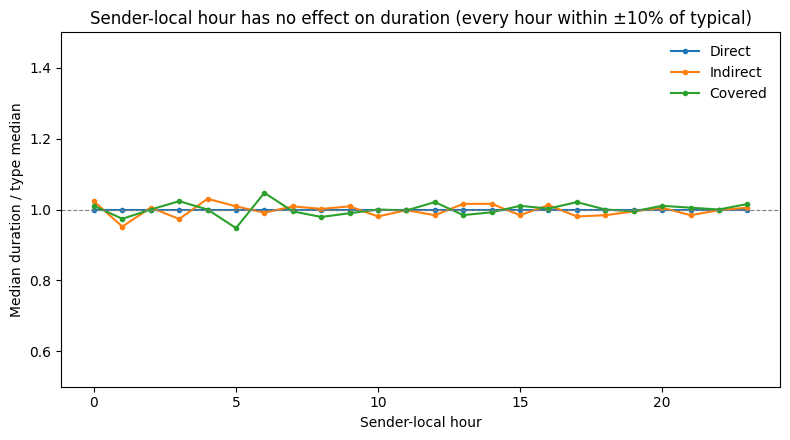

In [23]:
# Chart 2: duration by sender-local hour (baseline = each routing type's own median); fixed y-range so noise is not magnified
d = dur3.pivot(index='local_hour', columns='TRANSACTION_TYPE_CODE', values='med')[TYPES]
ax = (d / d.median()).plot(figsize=(8, 4.5), marker='.')
ax.axhline(1, color='grey', lw=0.8, ls='--'); ax.set_ylim(0.5, 1.5)
ax.set_title('Sender-local hour has no effect on duration (every hour within ±10% of typical)')
ax.set_xlabel('Sender-local hour'); ax.set_ylabel('Median duration / type median'); ax.legend(frameon=False)
savefig('dur3_by_local_hour')

**Findings (Duration)** (normal payments; ⟳ = check the printed value)
- **R-DUR1 Routing sets the speed:** median Direct 39 s, Indirect 281 s (~7×), Covered 383 s (~10×). Within Indirect and Covered, medians rise with every extra bank, but **not by a fixed number of seconds** (412 s at 4 banks → 1,043 s at 7). Covered is slower than Indirect only at 3 banks (288 vs 87 s); from 4 banks on they are the same. *But* duration is very noisy: routing explains only 4.6% of the variance of ln(duration), and even Direct payments have a p90 of 2,343 s.
- **R-DUR2 Country matters as much as routing:** sender and receiver country each add ~0.04 R² on top of routing (⟳ Direct-only additive R², fastest/slowest countries table). *Meaning:* each country's banks have their own processing speed (cut-offs, compliance checks).
- **R-DUR3 Scam payments take 10–20× longer:** median romance 1,148 s, CEO 741 s, account-replacement 571 s, duplicates 261 s vs 56 s normal. Fat-finger and customer-recall payments are as fast as normal (53 s). The gap remains per bank (473 vs 23 s per participant), so it is not just longer routes. *Meaning:* suspicious payments are held for screening. → share with Member 3.
- **N-DUR1 Sender-local hour and weekday have no effect** (extra R² 0.0001 and 0.0000; weekday medians identical within 2%).

**Evidence strength (Duration)** (⟳ = `ev02` values)
- **R-DUR1:** the 95% CIs of the medians don't overlap (Direct < Indirect < Covered). The Indirect/Direct ratio is stable every month and the test-period medians match. **Mechanism** at the median level, but individual durations are very noisy (R² ≈ 0.05).
- **R-DUR2:** country effects fitted on the first 2/3 of the time window keep most of their R² on the last 1/3 (⟳ compare with the in-sample R²; small countries are noisy). **Association:** each country's banks are slower or faster, for reasons the data doesn't show.
- **R-DUR3:** the scam delay remains **within the same routing type and hop count** (⟳ `dur5_anomaly_delay_same_routing`, Mann-Whitney p ≈ 0), so it is not caused by longer routes. **Association:** consistent with a screening hold, but the hold itself is not observed.
- **N-DUR1:** **Rejected**. This also holds on the data-inferred local clock.
- **Practical significance:** a correspondent route adds minutes at the median (⟳). Country speed ranges over two orders of magnitude, so speed promises must be country-specific.


## Feature group: FX conversions (`CURRENCY_CONVERSION_COUNT`)
Extends R-CCY2 (Direct, 97.8%) and R-CCY3 (conversions ≤ hops, 100%).

**Hypotheses**
- H-FX1: Conversions = the number of currency changes along the chain *payment currency → local currency of each bank on the path*.
  (Alternative H-FX1b: only changes between consecutive banks' local currencies, ignoring the payment currency.)
- H-FX2: At the same routing type and hop count, every conversion adds duration.

In [24]:
# Conversions by routing type and hop count (full data)
fx1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, CURRENCY_CONVERSION_COUNT, count(*) n, median(TOTAL_DURATION) med_dur
FROM p GROUP BY ALL ORDER BY ALL"""), 'fx1_conv_by_hops')
fx1.pivot_table(index=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT'], columns='CURRENCY_CONVERSION_COUNT', values='n', fill_value=0)

CURRENCY_CONVERSION_COUNT                      0          1          2         3         4        5        6       7       8      9      10    11    12   13   14   15   16   17
TRANSACTION_TYPE_CODE PARTICIPANT_COUNT                                                                                                                                         
Covered               3                   13500.0    53430.0   196133.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      4                    1324.0     5749.0    29169.0   60328.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      5                     117.0      576.0     3896.0   11616.0   19385.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      6                      11.0       71.0      474.0    1756.0    4704.0   6064.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      7                       3.0        7.0       58.0     230.0     815.0   1767.0   1945.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      8                       1.0        0.0        5.0      26.0     140.0    331.0    643.0   624.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      9                       0.0        0.0        1.0       7.0      13.0     63.0    164.0   242.0   195.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      10                      0.0        0.0        0.0       0.0       4.0      8.0     30.0    54.0    88.0   55.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      11                      0.0        0.0        0.0       0.0       0.0      2.0      4.0    14.0    22.0   28.0   22.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      12                      0.0        0.0        0.0       0.0       0.0      0.0      1.0     2.0     4.0    7.0   10.0   6.0   0.0  0.0  0.0  0.0  0.0  0.0
                      13                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     1.0    2.0    1.0   2.0   2.0  0.0  0.0  0.0  0.0  0.0
                      14                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    1.0    1.0   1.0   4.0  1.0  0.0  0.0  0.0  0.0
                      15                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   2.0  0.0  0.0  0.0  0.0  0.0
Direct                2                  991870.0  5331410.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
Indirect              3                   71789.0   451686.0  1537781.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      4                    7092.0    47223.0   218932.0  485569.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      5                     736.0     5067.0    27586.0   91388.0  153647.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      6                      84.0      538.0     3483.0   13555.0   36016.0  48945.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      7                       4.0       75.0      417.0    1839.0    6265.0  13594.0  15603.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      8                       0.0        8.0       52.0     262.0     911.0   2690.0   4951.0  4837.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      9                       0.0        0.0        5.0      27.0     129.0    417.0   109

In [25]:
# H-FX1: predict conversions from the path (20% sample, rows without the '...' gap)
# local currency of a bank = local_ccy of its BIC country (letters 5-6); banks in countries with no senders are unmapped
con.execute(f"CREATE OR REPLACE VIEW sp AS SELECT * FROM read_parquet('{SAMPLE.as_posix()}')")
fx_pred = sql("""
WITH s AS (SELECT rid, BIC8_PATH, CURRENCY_CODE FROM sp WHERE NOT path_gap),
h AS (SELECT rid, unnest(l) AS bic, unnest(range(1, len(l) + 1)) AS pos
      FROM (SELECT rid, string_split(BIC8_PATH, ';') AS l FROM s)),
seq AS (SELECT h.rid, h.pos, c.local_ccy AS ccy FROM h LEFT JOIN local_ccy c ON substr(h.bic, 5, 2) = c.cc
        UNION ALL SELECT rid, 0, CURRENCY_CODE FROM s),
chg AS (SELECT rid, pos, ccy, lag(ccy) OVER (PARTITION BY rid ORDER BY pos) AS prev FROM seq)
SELECT rid, bool_or(ccy IS NULL) AS unmapped,
       sum(CASE WHEN pos >= 1 AND ccy <> prev THEN 1 ELSE 0 END) AS pred_with_payccy,
       sum(CASE WHEN pos >= 2 AND ccy <> prev THEN 1 ELSE 0 END) AS pred_banks_only
FROM chg GROUP BY rid""")
con.register('fx_pred_df', fx_pred)
fx2 = save_table(sql("""
SELECT coalesce(TRANSACTION_TYPE_CODE, 'ALL') AS type, count(*) n,
       avg((pred_with_payccy = CURRENCY_CONVERSION_COUNT)::INT) AS acc_with_payment_ccy,
       avg((pred_banks_only  = CURRENCY_CONVERSION_COUNT)::INT) AS acc_banks_only
FROM sp JOIN fx_pred_df USING (rid) WHERE NOT unmapped
GROUP BY ROLLUP (TRANSACTION_TYPE_CODE) ORDER BY n DESC"""), 'fx2_conversion_prediction')
print(f"unmapped rows skipped: {fx_pred.unmapped.mean():.2%}")
fx_acc     = fx2.set_index('type').loc['ALL', 'acc_with_payment_ccy']
fx_acc_alt = fx2.set_index('type').loc['ALL', 'acc_banks_only']
fx2

unmapped rows skipped: 0.00%


,type,n,acc_with_payment_ccy,acc_banks_only
0,ALL,1848326,0.934838,1.0
1,Direct,1201892,0.947230,1.0
2,Indirect,573061,0.910845,1.0
3,Covered,73373,0.919248,1.0


In [26]:
# Where does the better predictor fail? (look for a pattern: anomaly, type, pair, payment currency = USD/EUR ...)
err = sql("""
SELECT sp.anomaly, TRANSACTION_TYPE_CODE, (CURRENCY_CONVERSION_COUNT - pred_with_payccy) AS actual_minus_pred, count(*) n
FROM sp JOIN fx_pred_df USING (rid) WHERE NOT unmapped AND pred_with_payccy <> CURRENCY_CONVERSION_COUNT
GROUP BY ALL ORDER BY n DESC LIMIT 25""")
save_table(err, 'fx2_prediction_errors')

,anomaly,TRANSACTION_TYPE_CODE,actual_minus_pred,n
0,NONE,Direct,-1.0,63383
1,NONE,Indirect,-1.0,51059
2,NONE,Covered,-1.0,5923
3,ROMANCE_SCAM,Indirect,-1.0,16
4,FAT_FINGER_MISTAKE,Direct,-1.0,14
5,ROMANCE_SCAM,Direct,-1.0,10
6,CEO_SCAM,Direct,-1.0,8
7,CEO_SCAM,Indirect,-1.0,6
8,FAT_FINGER_MISTAKE,Indirect,-1.0,6
9,DUPLICATE_PAYMENT,Direct,-1.0,6


In [27]:
# H-FX3: does the path explain R-CCY2's exceptions? Direct payments, full data:
# R-CCY2 uses the ordering/beneficiary BIC countries; the alternative uses the two banks actually on the path.
fx4 = save_table(sql("""
WITH d AS (SELECT p.*, string_split(BIC8_PATH, ';') l FROM p WHERE TRANSACTION_TYPE_CODE = 'Direct')
SELECT (d.l[1] = ORDERING_BIC8 AND d.l[-1] = BENEFICIARY_BIC8) AS endpoints_match, count(*) n,
       avg((CURRENCY_CONVERSION_COUNT = (lo.local_ccy <> lb.local_ccy)::INT)::INT) AS acc_rccy2_ordering_beneficiary,
       avg((CURRENCY_CONVERSION_COUNT = (l1.local_ccy <> l2.local_ccy)::INT)::INT) AS acc_path_banks
FROM d LEFT JOIN local_ccy lo ON d.o_cc = lo.cc            LEFT JOIN local_ccy lb ON d.b_cc = lb.cc
       LEFT JOIN local_ccy l1 ON substr(d.l[1], 5, 2) = l1.cc LEFT JOIN local_ccy l2 ON substr(d.l[-1], 5, 2) = l2.cc
GROUP BY 1 ORDER BY 1"""), 'fx4_rccy2_exceptions')
w4 = lambda c: np.average(fx4[c].fillna(0), weights=fx4.n)
fx4_old, fx4_new = w4('acc_rccy2_ordering_beneficiary'), w4('acc_path_banks')
print(f"Direct: R-CCY2 (ordering/beneficiary BIC) {fx4_old:.2%} vs path banks {fx4_new:.2%}")
fx4

Direct: R-CCY2 (ordering/beneficiary BIC) 97.80% vs path banks 100.00%


,endpoints_match,n,acc_rccy2_ordering_beneficiary,acc_path_banks
0,False,615519,0.773583,1.0
1,True,5707761,1.000000,1.0


In [28]:
# H-FX2: at fixed routing type + hops, does each conversion add duration?
d = fx1[(fx1.TRANSACTION_TYPE_CODE != 'Direct') & (fx1.n >= 1000)]
fx3 = d.pivot_table(index=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT'], columns='CURRENCY_CONVERSION_COUNT', values='med_dur')
save_table(fx3.reset_index(), 'fx3_duration_by_conversions')
fx_dur_extra = r2(sn, base + ['CURRENCY_CONVERSION_COUNT']) - r2_base
print(f'extra R² of conversions on ln(duration) given type + hops: {fx_dur_extra:.4f}')
fx3

extra R² of conversions on ln(duration) given type + hops: 0.0004


CURRENCY_CONVERSION_COUNT                    0      1      2       3       4       5       6       7       8
TRANSACTION_TYPE_CODE PARTICIPANT_COUNT                                                                     
Covered               3                  362.0  298.0  279.0     NaN     NaN     NaN     NaN     NaN     NaN
                      4                  458.0  435.0  444.0   446.0     NaN     NaN     NaN     NaN     NaN
                      5                    NaN    NaN  572.0   596.5   582.0     NaN     NaN     NaN     NaN
                      6                    NaN    NaN    NaN   747.0   727.5   763.5     NaN     NaN     NaN
                      7                    NaN    NaN    NaN     NaN     NaN   966.0   922.0     NaN     NaN
Indirect              3                  134.0   96.0   83.0     NaN     NaN     NaN     NaN     NaN     NaN
                      4                  422.5  414.0  413.0   412.0     NaN     NaN     NaN     NaN     NaN
                      5                    NaN  592.0  583.5   578.0   600.0     NaN     NaN     NaN     NaN
                      6                    NaN    NaN  702.0   769.0   786.5   835.0     NaN     NaN     NaN
                      7                    NaN    NaN    NaN  1009.0  1014.0  1037.0  1066.0     NaN     NaN
                      8                    NaN    NaN    NaN     NaN     NaN  1230.5  1235.0  1314.0     NaN
                      9                    NaN    NaN    NaN     NaN     NaN     NaN  1491.0  1452.0  1514.0

In [29]:
# Evidence (FX): CI of the exact-match accuracy, an out-of-sample test (local currencies re-learned on the first 2/3 of
# time, rule scored on sample rows from the last 1/3) and the share of money that is converted
con.execute(f"""CREATE OR REPLACE TABLE local_ccy_tr AS SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
               (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p WHERE EPOCH_SECONDS < {T_SPLIT} GROUP BY ALL) GROUP BY o_cc""")
fx_oos = sql(f"""
WITH s AS (SELECT rid, BIC8_PATH, CURRENCY_CONVERSION_COUNT y FROM sp WHERE NOT path_gap AND EPOCH_SECONDS >= {T_SPLIT}),
h AS (SELECT rid, unnest(l) AS bic, unnest(range(1, len(l) + 1)) AS pos FROM (SELECT rid, string_split(BIC8_PATH, ';') AS l FROM s)),
seq AS (SELECT h.rid, h.pos, c.local_ccy AS ccy FROM h LEFT JOIN local_ccy_tr c ON substr(h.bic, 5, 2) = c.cc),
chg AS (SELECT rid, pos, ccy, lag(ccy) OVER (PARTITION BY rid ORDER BY pos) AS prev FROM seq),
pr AS (SELECT rid, bool_or(ccy IS NULL) unmapped, sum(CASE WHEN pos >= 2 AND ccy <> prev THEN 1 ELSE 0 END) pred FROM chg GROUP BY rid)
SELECT count(*) n, sum((pred = y)::INT) k FROM pr JOIN s USING (rid) WHERE NOT unmapped""").iloc[0]
fx3_t = sql(f"""WITH d AS (SELECT p.*, string_split(BIC8_PATH, ';') l FROM p WHERE TRANSACTION_TYPE_CODE = 'Direct')
  SELECT strftime(ts, '%Y-%m') AS month, EPOCH_SECONDS >= {T_SPLIT} AS test, count(*) n,
         sum((CURRENCY_CONVERSION_COUNT = (l1.local_ccy <> l2.local_ccy)::INT)::INT) k,
         sum((CURRENCY_CONVERSION_COUNT = (t1.local_ccy <> t2.local_ccy)::INT)::INT) k_tr
  FROM d LEFT JOIN local_ccy l1 ON substr(d.l[1], 5, 2) = l1.cc LEFT JOIN local_ccy l2 ON substr(d.l[-1], 5, 2) = l2.cc
         LEFT JOIN local_ccy_tr t1 ON substr(d.l[1], 5, 2) = t1.cc LEFT JOIN local_ccy_tr t2 ON substr(d.l[-1], 5, 2) = t2.cc
  GROUP BY ALL""")
f3 = fx3_t.sum(numeric_only=True); f3te = fx3_t[fx3_t.test].sum(numeric_only=True)
f3m = fx3_t.groupby('month')[['n', 'k']].sum(); f3m = f3m[f3m.n >= 0.02 * f3m.n.sum()]
n_all = fx2.set_index('type').loc['ALL', 'n']
conv = sql("""SELECT CURRENCY_CONVERSION_COUNT k, count(*) n, sum(USD_AMOUNT) usd FROM p GROUP BY 1 ORDER BY 1""")
conv_share = conv.loc[conv.k > 0, 'usd'].sum() / conv.usd.sum()
fx_by_type = fx2.set_index('type').acc_banks_only.drop('ALL')
ev02 += [
 dict(id='R-FX1', statistic_ci=share_ci(fx_acc_alt * n_all, n_all, 3),
      out_of_sample=f"train-only local currencies, test-period rows: {share_ci(fx_oos.k, fx_oos.n, 3)}",
      **holdout(fx_oos.n and abs(fx_oos.k / fx_oos.n - fx_acc_alt) < 0.001, 'test-period accuracy within 0.1 points of the full data'),
      invariance='by routing type ' + ', '.join(f'{t} {v:.3%}' for t, v in fx_by_type.items()), causal_status='Mechanism',
      practical_significance=f'{conv_share:.1%} of USD value is converted at least once; every observed bank-currency change is associated with one recorded FX step; fees are not measured in this dataset'),
 dict(id='N-FX2', statistic_ci=share_ci(fx_acc * n_all, n_all, 2), causal_status='Rejected', practical_significance='-'),
 dict(id='R-FX3', statistic_ci=f'path banks {share_ci(f3.k, f3.n, 3)} vs ordering/beneficiary BIC {fx4_old:.2%}', causal_status='Mechanism',
      out_of_sample=f'test period, train-only local currencies: {share_ci(f3te.k_tr, f3te.n, 3)}',
      **holdout(abs(f3te.k_tr / f3te.n - f3.k / f3.n) < 0.001, 'test-period accuracy within 0.1 points of the full data'),
      invariance=f'by month {(f3m.k / f3m.n).min():.3%}-{(f3m.k / f3m.n).max():.3%}',
      practical_significance='explains the R-CCY2 exceptions: FX follows the banks that actually process the payment'),
 dict(id='N-FX1', statistic_ci=f'extra R² {fx_dur_extra:.4f}', causal_status='Rejected', practical_significance='No material incremental duration explanation was found for FX count in the fitted model; zero causal delay cannot be established'),
]

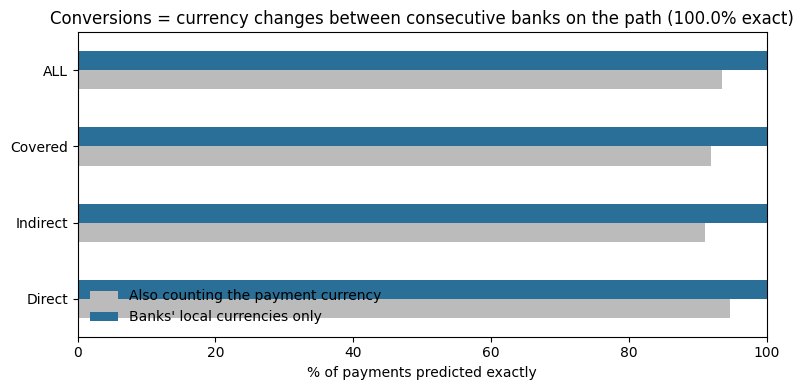

In [30]:
# Chart: accuracy of the two FX rules (baseline = rule that also counts the payment currency)
d = fx2.set_index('type')[['acc_with_payment_ccy', 'acc_banks_only']].reindex(TYPES + ['ALL']).dropna() * 100
ax = d.plot.barh(figsize=(8, 4), color=['#bbbbbb', '#2a6f97'])
ax.set_title(f'Conversions = currency changes between consecutive banks on the path ({fx_acc_alt:.1%} exact)')
ax.set_xlabel('% of payments predicted exactly'); ax.set_ylabel(''); ax.set_xlim(0, 100)
ax.legend(['Also counting the payment currency', 'Banks\' local currencies only'], frameon=False, loc='lower left')
savefig('fx2_conversion_prediction')

**Findings (FX)** (⟳ = check the printed value)
- **R-FX1 Conversions = number of times the local currency changes between consecutive banks on the path.** Exact for 100% of complete paths (1.85M rows in the 20% sample; Direct, Indirect and Covered alike). The payment currency itself is **not** counted. *Meaning:* each bank converts only when it passes the payment to a bank in a different currency zone. Extends R-CCY2 (Direct only) and R-CCY3 (conversions ≤ hops) to every routing type.
- **N-FX2 Counting the payment currency as well is wrong:** only 93.5% exact; it over-counts by exactly 1 in every error.
- **R-FX3 The path explains R-CCY2's exceptions** (⟳ `fx4`): R-CCY2 used the ordering/beneficiary BIC, but in ~5% of rows each the path starts or ends at a different bank. Using the banks actually on the path should take Direct accuracy from 97.8% to ~100%. → tell the currency teammate.
- **N-FX1 Conversions don't add time:** at the same routing type and hop count, median duration is flat across conversion counts (extra R² 0.0004).
- *Caveat:* each country's local currency is inferred from the data (the currency its senders use most), and paths with a `...` gap cannot be tested.

**Evidence strength (FX)** (⟳ = `ev02` values)
- **R-FX1:** exact for ~100% of complete paths. The Wilson CI lower bound is close to 100%. It also holds out of sample: local currencies are re-learned on the first 2/3 of the time window and the rule is scored on the last 1/3. It holds for every routing type. **Mechanism.**
- **R-FX3:** **Mechanism.** It explains the R-CCY2 exceptions.
- **N-FX1 / N-FX2:** **Rejected.**
- **Practical significance:** ⟳ the share of USD value that is converted at least once. Each currency-zone change on the path adds one FX conversion (one fee), and FX adds no time.



## Rules for this notebook
All values and verdicts are computed from the results above. Verdict scale: Confirmed (≥ 99% / effect matches) · Strong (95–99%) · Partial (70–95% or subgroup) · Rejected.
If a printed value contradicts the Findings text, update the Findings text, not the numbers.


In [31]:
dur_extra = dur_r2['extra_r2_given_type_hops']
time_extra = max(dur_extra.get('local_hour', 0), dur_extra.get('local_wd', 0))
nogap = ~rt2.path_gap
rt3_len_share = np.average(rt2.loc[nogap, 'path_len_eq_participants'], weights=rt2.loc[nogap, 'n'])
mono = all(np.all(np.diff(dur1[(dur1.TRANSACTION_TYPE_CODE == t) & (dur1.n >= 1000)].sort_values('PARTICIPANT_COUNT').med) > 0)
           for t in ['Indirect', 'Covered'])
order_ok = med_type['Direct'] < med_type['Indirect'] < med_type['Covered']
d4 = sql("SELECT anomaly, median(TOTAL_DURATION) med FROM p GROUP BY 1").set_index('anomaly').med
scam_x = {a: d4[a] / d4['NONE'] for a in ['ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM'] if a in d4}
lvl = lambda x, a, b: 'Confirmed' if x <= a else 'Strong' if x <= b else 'Partial'
rules = [
    dict(id='R-RT1', group='Routing',
         rule='Direct payments involve exactly 2 banks; Indirect and Covered payments involve 3 or more',
         test='share of rows where (type = Direct) <=> (PARTICIPANT_COUNT = 2), full data',
         value=f'{rt1_share:.2%}', verdict=verdict_from_share(rt1_share),
         evidence_files='rt1_hops_by_type.csv; rt1_hops_by_type.png',
         interpretation='Direct = the two banks hold accounts with each other; otherwise correspondent banks relay the payment'),
    dict(id='R-RT6', group='Routing',
         rule=f'The number of intermediary banks is geometric: each further intermediary is added with probability q = {q_hop:.3f}; Indirect and Covered share the same hop distribution',
         test='total variation distance between observed and geometric distribution of PARTICIPANT_COUNT - 2, full data',
         value=f'q = {q_hop:.4f}; distance = {rt6_tvd:.4f}', verdict=lvl(rt6_tvd, 0.005, 0.02),
         evidence_files='rt6_intermediaries_geometric.csv; rt1_hops_by_type.csv',
         interpretation='Banks use the shortest correspondent chain available, so each extra hop is rarer'),
    dict(id='R-RT3', group='Routing',
         rule='PARTICIPANT_COUNT = number of BIC entries on the path, repeated BICs counted (complete paths)',
         test='share of rows without a path gap where path_len = PARTICIPANT_COUNT, full data',
         value=f'{rt3_len_share:.2%}', verdict=verdict_from_share(rt3_len_share),
         evidence_files='rt2_path_vs_participants.csv',
         interpretation='A bank that handles the payment twice counts twice'),
    dict(id='R-RT2', group='Routing',
         rule='The path starts at the ordering BIC and ends at the beneficiary BIC; in ~5% of rows each end is a different (usually foreign) bank',
         test='share of rows, full data, every routing type', value=f'start {rt2_start:.2%}; end {rt2_end:.2%}',
         verdict=verdict_from_share(min(rt2_start, rt2_end)),
         evidence_files='rt2_path_vs_participants.csv; rt2_first_bank_mismatch.csv; rt2_currency_vs_first_bank.csv',
         interpretation='A parent/branch BIC or an outsourced sending/receiving bank processes the payment'),
    dict(id='R-RT5', group='Routing',
         rule=(f"Observed continuity-gap ('...') frequencies are consistent with a model in which each link independently has about a {q_link:.1%} chance of a gap: it fits every path length within sampling error (independence itself is not proven)"
               if rt5_gof_p >= 0.01 else
               f"Approximate candidate model: each link has about a {q_link:.1%} chance of a continuity gap ('...'); a goodness-of-fit test rejects exact per-link independence (largest miss {rt5_maxerr:.1%} points)"),
         test='chi-square goodness of fit: observed gap rate vs 1-(1-q)^(participants-1) for every path length with >= 1000 rows (q from Direct rows only), full data',
         value=f'goodness of fit chi-square {rt5_chi:.1f} on {rt5_df} df, p = {rt5_gof_p:.2f}; largest error {rt5_maxerr:.4f} (|z| = {rt5_zmax:.1f})',
         verdict='Confirmed' if rt5_gof_p >= 0.01 else lvl(rt5_maxerr, 0.005, 0.01),
         evidence_files='rt5_gap_by_participants.csv',
         interpretation='Longer chains have more hand-overs where tracking can break'),
    dict(id='R-RT7', group='Routing',
         rule='Routing type has negligible measured association with the business/consumer pair (not proof of independent assignment)',
         test="Cramér's V (routing type x pair), full data", value=f"V = {rt4_v['pair']:.4f}",
         verdict='Confirmed' if rt4_v['pair'] < 0.01 else 'Rejected',
         evidence_files='rt4_type_by_pair.csv',
         interpretation='Routing patterns are very similar across B/C pair types; the data do not identify whether customer type enters the generator directly'),
    dict(id='R-RT8', group='Routing',
         rule='Domestic payments are routed Covered more often than cross-border ones; the Direct share is the same',
         test="Covered share domestic vs cross-border; Cramér's V, full data",
         value=f"Covered {cov_dom:.2f}% vs {cov_xb:.2f}%; V = {rt4_v['cross_border']:.4f}",
         verdict='Confirmed' if cov_dom > 1.5 * cov_xb else 'Rejected',
         evidence_files='rt4_type_by_cross_border.csv',
         interpretation='Counter-intuitive (cover payments are normally cross-border): likely a feature of how the data was generated'),
    dict(id='R-DUR1', group='Duration',
         rule='Median duration rises with routing type (Direct < Indirect < Covered) and with every extra bank on the path',
         test='median duration by type and hop count (normal rows, full data); R² of ln(duration) on type + hops (20% sample)',
         value='medians ' + ', '.join(f'{t} {med_type.get(t, np.nan):.0f}s' for t in TYPES) + f'; R² {r2_base:.3f} (noisy)',
         verdict='Confirmed' if (mono and order_ok) else 'Partial',
         evidence_files='dur1_by_type_hops.csv; dur1_by_type_hops.png; dur2_factor_screening.csv',
         interpretation='Plausibly each correspondent bank adds processing and queueing time (not observed directly)'),
    dict(id='R-DUR2', group='Duration',
         rule="Sender and receiver country each add their own delay, about as much as routing does",
         test='R² of ln(duration) on sender + receiver country, Direct payments only (additive, 20% sample)',
         value=f"sender {dur_cc['sender country']:.3f}; receiver {dur_cc['receiver country']:.3f}; both {dur_cc['sender + receiver (additive)']:.3f}",
         verdict='Confirmed' if dur_cc['sender + receiver (additive)'] >= 0.01 else 'Rejected',
         evidence_files='dur2_factor_screening.csv; dur2_country_speed_direct.csv',
         interpretation="Plausibly each country's banks have their own processing speed (cut-off times, compliance checks); the cause is not identified in the data"),
    dict(id='R-DUR3', group='Duration',
         rule='Scam payments take longer than normal payments with the same routing type and hop count; fat-finger and duplicate payments barely differ',
         test='median duration ratio vs normal payments with the same routing type and hop count (Mann-Whitney), full data', value='same routing: ' + '; '.join(f'{a} x{r.x_vs_normal_same_routing:.1f}' for a, r in scam_adj.iterrows()) + ' | unadjusted: ' + '; '.join(f'{k} x{v:.1f}' for k, v in scam_x.items()),
         verdict='Confirmed' if scam_x and min(scam_x.values()) >= 5 else 'Partial',
         evidence_files='dur4_by_anomaly.csv',
         interpretation='Consistent with a screening hold before release, but the hold itself is not observed: a plausible mechanism, not a proven cause'),
    dict(id='N-DUR1', group='Duration',
         rule='Sender-local hour / weekday changes duration',
         test='extra R² of ln(duration) beyond type + hops', value=f'hour {dur_extra.get("local_hour", np.nan):.4f}; weekday {dur_extra.get("local_wd", np.nan):.4f}',
         verdict='Rejected' if time_extra < 0.003 else 'Partial',
         evidence_files='dur3_by_local_hour.csv; dur3_by_local_weekday.csv; dur3_by_local_hour.png',
         interpretation='In the fitted model, inferred local hour and weekday add negligible explanatory power; a zero causal effect is not established'),
    dict(id='R-FX1', group='FX',
         rule='Conversions = number of local-currency changes between consecutive banks on the path (payment currency not counted)',
         test='exact prediction accuracy, 20% sample, paths without a gap', value=f'{fx_acc_alt:.2%}',
         verdict=verdict_from_share(fx_acc_alt),
         evidence_files='fx2_conversion_prediction.csv; fx2_conversion_prediction.png',
         interpretation='Each bank converts only when it hands the payment to a bank in another currency zone; extends R-CCY2 and R-CCY3'),
    dict(id='N-FX2', group='FX',
         rule='Conversions also count the change from the payment currency to the first bank',
         test='exact prediction accuracy, same rows', value=f'{fx_acc:.2%} (always over-counts by 1)',
         verdict='Rejected', evidence_files='fx2_conversion_prediction.csv; fx2_prediction_errors.csv',
         interpretation='The first bank does not convert the payment currency'),
    dict(id='R-FX3', group='FX',
         rule='R-CCY2 exceptions disappear when the banks actually on the path are used instead of the ordering/beneficiary BIC',
         test='accuracy on all Direct rows, full data', value=f'path banks {fx4_new:.2%} vs ordering/beneficiary {fx4_old:.2%}',
         verdict=verdict_from_share(fx4_new),
         evidence_files='fx4_rccy2_exceptions.csv',
         interpretation='Conversions follow the banks that process the payment (see R-RT2)'),
    dict(id='N-FX1', group='FX',
         rule='At the same routing and hop count, extra conversions add duration',
         test='extra R² of conversions on ln(duration) given type + hops', value=f'{fx_dur_extra:.4f}',
         verdict='Rejected' if fx_dur_extra < 0.003 else 'Partial',
         evidence_files='fx3_duration_by_conversions.csv',
         interpretation='After adjusting for type and hop count, FX conversions add negligible explanatory power in the tested model; a causal zero effect is not proven'),
]
pd.DataFrame(rules, columns=RULE_COLS).to_csv(RULES / 'rules_02.csv', index=False)
log = combine_rules()
log.loc[log.source == 'rules_02.csv', ['id', 'group', 'value', 'verdict']]

,id,group,value,verdict
0,R-RT1,Routing,100.00%,Confirmed
1,R-RT6,Routing,q = 0.3677; distance = 0.0001,Confirmed
2,R-RT3,Routing,100.00%,Confirmed
3,R-RT2,Routing,start 95.02%; end 95.01%,Strong
4,R-RT5,Routing,"goodness of fit chi-square 13.5 on 8 df, p = 0...",Confirmed
5,R-RT7,Routing,V = 0.0024,Confirmed
6,R-RT8,Routing,Covered 7.34% vs 3.92%; V = 0.0459,Confirmed
7,R-DUR1,Duration,"medians Direct 39s, Indirect 281s, Covered 383...",Confirmed
8,R-DUR2,Duration,sender 0.051; receiver 0.046; both 0.091,Confirmed
9,R-DUR3,Duration,same routing: ACCOUNT_REPLACEMENT_SCAM x5.8; C...,Confirmed


In [32]:
# Evidence file for this notebook (merged with the rules into outputs/tables/evidence_matrix.csv by notebook 04, section 5)
ev02_df = save_evidence(ev02, '02')
ev02_df.set_index('id')[['statistic_ci', 'out_of_sample', 'causal_status']]

,statistic_ci,out_of_sample,causal_status
id,,,
R-RT1,"100.0000% [100.0000%, 100.0000%], n = 10,000,000",holds by definition in every period,Structural
R-RT6,"q = 36.77% [36.74%, 36.80%], n = 10,000,000",q fitted on train = 0.3677; distance to the te...,Mechanism
R-RT3,100.00% of complete paths,NaN,Structural
R-RT2,"start 95.02% [95.00%, 95.03%], n = 10,000,000;...","test period: start 95.01%, end 95.01%",Association
R-RT5,"per-link gap chance 4.99% [4.97%, 5.00%], n = ...",gap chance fitted on train Direct rows = 0.049...,Mechanism
R-RT7,"V = 0.0024 [0.0020, 0.0029]",test period V = 0.0027,Mechanism
R-RT8,Covered domestic - cross-border +3.43% [+3.37%...,"test period +3.36% [+3.26%, +3.47%]",Association
R-DUR1,"median (95% CI): Direct 39s [39, 39], Indirect...","test-period medians: Direct 39s, Indirect 280s...",Mechanism
R-DUR2,"additive R² 0.091 (Direct, 20% sample; point e...","country effects fitted on train, R² on test 0.090",Association



## Power BI hand-off
Import these CSVs from `outputs/tables/` (all small; keep the column names exactly as they are):

| Page | Files | Rules |
|---|---|---|
| Routing | `rt1_hops_by_type`, `rt6_intermediaries_geometric`, `rt2_path_vs_participants`, `rt5_gap_by_participants`, `rt4_type_by_pair`, `rt4_type_by_cross_border` | R-RT1, R-RT6, R-RT3, R-RT2, R-RT5, R-RT7, R-RT8 |
| Duration | `dur1_by_type_hops`, `dur2_country_speed_direct`, `dur4_by_anomaly`, `dur3_by_local_hour` | R-DUR1, R-DUR2, R-DUR3, N-DUR1 |
| FX | `fx2_conversion_prediction`, `fx4_rccy2_exceptions`, `fx3_duration_by_conversions` | R-FX1, N-FX2, R-FX3, N-FX1 |

Each page: a text box with the rule + its value from `rules_02.csv`, one chart per rule against a baseline, and a takeaway title.
